# Model Selection and Evaluation

## Objective

Systematically compare candidate machine learning models for donor corneal tissue grading using the specialist-labelled dataset.

The target variable is `Tissue_Grade_Clean`, with three classes: A+, A, and B.

## Experimental Plan

1. Load the prepared dataset and establish a reproducible training setup.
2. Compare candidate models using consistent stratified cross-validation folds.
3. Evaluate performance using accuracy, balanced accuracy, macro F1, and per-class metrics.
4. Analyse misclassification patterns and compare model behaviour.
5. Select a promising candidate for subsequent hyperparameter tuning and explainability analysis.

## Evaluation Principles

- Fit preprocessing steps within each cross-validation fold to avoid data leakage.
- Use the same training records and folds when comparing models.
- Prioritise macro F1 and balanced accuracy alongside accuracy because the target classes are imbalanced.
- Keep model selection separate from hyperparameter tuning and final evaluation.
- Treat previously examined holdout results as exploratory rather than as an independent final performance estimate.

## Scope

This notebook focuses on systematic model comparison and selection. Detailed hyperparameter tuning, explainability analysis, and independent final evaluation will be addressed in subsequent stages.

In [9]:

from pathlib import Path

sys.path.insert(0, str(Path("../scripts").resolve()))

import modeling_setup as ms

print("Module loaded from:", ms.__file__)

Module loaded from: C:\Users\pulit\OneDrive\Desktop\University\Y4S1\research\xai-cornea-grading\ml\grading\scripts\modeling_setup.py


In [2]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("../data/processed/cleaned_grading_dataset.xlsx")
df = pd.read_excel(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumn names:")
for column in df.columns:
    print(repr(column))

print("\nColumns containing 'Grade':")
print([column for column in df.columns if "grade" in str(column).lower()])

Dataset shape: (1054, 116)

Column names:
'Tissue_ID'
'Eye'
'Image_ID'
'Disease_Label'
'Disease_Severity'
'ECD_CD_cells_per_mm2'
'CV'
'HEX_percent'
'SD'
'Total_Cell_Count'
'Total_Area_um2'
'Epithelium_Findings'
'Epithelium_Severity'
'Stroma_Findings'
'Stroma_Severity'
'Descemet_Findings'
'Descemet_Severity'
'Endothelium_Findings'
'Endothelium_Severity'
'Additional_Findings'
'Tissue_Grade'
'Overall_Donor_Quality'
'Transplant_Suitability'
'Suitability_Reason'
'Primary_COD'
'Donor_Age'
'Tissue_Serial'
'Linkage_Status'
'Source_PDF'
'PDF_Pages'
'Konan_Report_File'
'SP_Image_File'
'Cell_Image_File'
'Konan_Raw_CorneaID'
'Konan_Exam_Date'
'Konan_Mean_Cell_Area_um2'
'Konan_Comments'
'Donor_Sex'
'Admitting_Diagnosis'
'Death_Date_Time'
'Preservation_Date_Time'
'Death_to_Preservation_Time'
'Storage_Medium'
'Serology_HBsAg'
'Serology_HCV'
'Serology_HIV'
'Serology_VDRL'
'Lens_Status'
'Form_ECD_cells_per_mm2'
'Intended_Use'
'Tissue_Outcome'
'Recipient_Age'
'Recipient_Eye'
'Recipient_Indication'
'Requ

In [11]:
from modeling_setup import (
    load_labelled_data,
    get_holdout_split,
    make_preprocessor,
    make_cv,
    TARGET,
    ALL_FEATURES,
    NUMERIC_FEATURES,
)

labelled_df = load_labelled_data()
train_df, test_df = get_holdout_split(labelled_df)

X_train = train_df[ALL_FEATURES]
y_train = train_df[TARGET]
cv = make_cv()

print("Labelled dataset:", labelled_df.shape)
print("Training set:", train_df.shape)
print("Test set:", test_df.shape)
print("Training class counts:", y_train.value_counts().to_dict())
print("Test class counts:", test_df[TARGET].value_counts().to_dict())
print("Number of features:", len(ALL_FEATURES))

Saved holdout split to ..\data\processed\holdout_split.csv
Labelled dataset: (1036, 116)
Training set: (828, 116)
Test set: (208, 116)
Training class counts: {'A+': 436, 'A': 255, 'B': 137}
Test class counts: {'A+': 109, 'A': 64, 'B': 35}
Number of features: 24


In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

rf = Pipeline([
    (
        "preprocessor",
        ms.make_preprocessor(binary=[], categorical=[])
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

scores = cross_val_score(
    rf,
    train_df[ms.NUMERIC_FEATURES],
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print("Fold macro F1 scores:", scores.round(4))
print("Mean macro F1:", round(scores.mean(), 4))
print("Standard deviation:", round(scores.std(), 4))

Fold macro F1 scores: [0.8554 0.8386 0.7744 0.8531 0.8442]
Mean macro F1: 0.8332
Standard deviation: 0.03


In [13]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "SVM (RBF)": SVC(
        class_weight="balanced",
        random_state=42
    ),
}

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "macro_f1": "f1_macro",
}

results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", ms.make_preprocessor()),
        ("classifier", model),
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise",
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Balanced Accuracy": scores["test_balanced_accuracy"].mean(),
        "Macro F1": scores["test_macro_f1"].mean(),
        "Macro F1 SD": scores["test_macro_f1"].std(),
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

print(results_df.round(4).to_string(index=False))

              Model  Accuracy  Balanced Accuracy  Macro F1  Macro F1 SD
      Random Forest    0.8382             0.8267    0.8337       0.0262
          SVM (RBF)    0.7935             0.7811    0.7893       0.0279
        Extra Trees    0.7778             0.7424    0.7541       0.0315
Logistic Regression    0.7295             0.7315    0.7193       0.0139


In [14]:
from pathlib import Path

RESULTS_PATH = Path("../data/processed/model_comparison_cv.csv")
RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)

results_df.to_csv(RESULTS_PATH, index=False)

print("Saved model comparison to:", RESULTS_PATH)
print("Best candidate:", results_df.iloc[0]["Model"])
print("Best macro F1:", round(results_df.iloc[0]["Macro F1"], 4))

Saved model comparison to: ..\data\processed\model_comparison_cv.csv
Best candidate: Random Forest
Best macro F1: 0.8337


In [15]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

rf_pipeline = Pipeline([
    ("preprocessor", ms.make_preprocessor()),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

oof_predictions = cross_val_predict(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict",
    n_jobs=-1
)

print("Per-class performance:")
print(classification_report(
    y_train,
    oof_predictions,
    labels=ms.CLASSES,
    target_names=ms.CLASSES,
    digits=4,
    zero_division=0
))

print("Confusion matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(
    confusion_matrix(y_train, oof_predictions, labels=ms.CLASSES),
    index=[f"Actual {c}" for c in ms.CLASSES],
    columns=[f"Predicted {c}" for c in ms.CLASSES]
))

Per-class performance:
              precision    recall  f1-score   support

          A+     0.8802    0.8761    0.8782       436
           A     0.7343    0.7804    0.7567       255
           B     0.9187    0.8248    0.8692       137

    accuracy                         0.8382       828
   macro avg     0.8444    0.8271    0.8347       828
weighted avg     0.8416    0.8382    0.8393       828

Confusion matrix (rows = actual, columns = predicted):
           Predicted A+  Predicted A  Predicted B
Actual A+           382           52            2
Actual A             48          199            8
Actual B              4           20          113


In [16]:
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
import pandas as pd

svm_pipeline = Pipeline([
    ("preprocessor", ms.make_preprocessor()),
    ("classifier", SVC(class_weight="balanced", random_state=42))
])

svm_predictions = cross_val_predict(
    svm_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict",
    n_jobs=-1
)

print("SVM — Per-class performance:")
print(classification_report(
    y_train,
    svm_predictions,
    labels=ms.CLASSES,
    target_names=ms.CLASSES,
    digits=4,
    zero_division=0
))

SVM — Per-class performance:
              precision    recall  f1-score   support

          A+     0.8430    0.8372    0.8400       436
           A     0.6752    0.7255    0.6994       255
           B     0.8843    0.7810    0.8295       137

    accuracy                         0.7935       828
   macro avg     0.8008    0.7812    0.7896       828
weighted avg     0.7981    0.7935    0.7950       828



In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessor", ms.make_preprocessor()),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

param_grid = {
    "classifier__n_estimators": [300, 500],
    "classifier__max_depth": [None, 15, 25],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2],
    "classifier__max_features": ["sqrt", 0.8],
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("Best CV macro F1:", round(grid_search.best_score_, 4))
print("Best parameters:")
for name, value in grid_search.best_params_.items():
    print(f"  {name}: {value}")

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best CV macro F1: 0.8535
Best parameters:
  classifier__max_depth: 15
  classifier__max_features: sqrt
  classifier__min_samples_leaf: 1
  classifier__min_samples_split: 5
  classifier__n_estimators: 300


In [18]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

best_rf = grid_search.best_estimator_

tuned_oof_predictions = cross_val_predict(
    best_rf,
    X_train,
    y_train,
    cv=cv,
    method="predict",
    n_jobs=-1
)

print("Tuned Random Forest — Per-class performance:")
print(classification_report(
    y_train,
    tuned_oof_predictions,
    labels=ms.CLASSES,
    target_names=ms.CLASSES,
    digits=4,
    zero_division=0
))

print("Confusion matrix:")
print(pd.DataFrame(
    confusion_matrix(
        y_train,
        tuned_oof_predictions,
        labels=ms.CLASSES
    ),
    index=[f"Actual {c}" for c in ms.CLASSES],
    columns=[f"Predicted {c}" for c in ms.CLASSES]
))

Tuned Random Forest — Per-class performance:
              precision    recall  f1-score   support

          A+     0.8879    0.8899    0.8889       436
           A     0.7527    0.8118    0.7811       255
           B     0.9741    0.8248    0.8933       137

    accuracy                         0.8551       828
   macro avg     0.8716    0.8422    0.8544       828
weighted avg     0.8605    0.8551    0.8564       828

Confusion matrix:
           Predicted A+  Predicted A  Predicted B
Actual A+           388           48            0
Actual A             45          207            3
Actual B              4           20          113


In [19]:
tuning_results = pd.DataFrame(grid_search.cv_results_)

tuning_results = tuning_results.sort_values(
    "rank_test_score"
)

tuning_path = ms.SPLIT_PATH.parent / "random_forest_tuning_results.csv"
tuning_results.to_csv(tuning_path, index=False)

print("Saved tuning results to:", tuning_path)
print("\nBest parameters:")
print(grid_search.best_params_)
print("Best mean CV macro F1:", round(grid_search.best_score_, 4))

Saved tuning results to: ..\data\processed\random_forest_tuning_results.csv

Best parameters:
{'classifier__max_depth': 15, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 300}
Best mean CV macro F1: 0.8535


In [20]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)
import pandas as pd

X_test = test_df[ms.ALL_FEATURES]
y_test = test_df[ms.TARGET]

test_predictions = best_rf.predict(X_test)

print("FINAL HOLDOUT TEST RESULTS")
print("=" * 40)
print("Test samples:", len(y_test))
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 4))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_test, test_predictions), 4
))
print("Macro F1:", round(
    f1_score(y_test, test_predictions, average="macro"), 4
))

print("\nPer-class classification report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=ms.CLASSES,
    target_names=ms.CLASSES,
    digits=4,
    zero_division=0,
))

print("Confusion matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(
    confusion_matrix(y_test, test_predictions, labels=ms.CLASSES),
    index=[f"Actual {c}" for c in ms.CLASSES],
    columns=[f"Predicted {c}" for c in ms.CLASSES],
))

FINAL HOLDOUT TEST RESULTS
Test samples: 208
Accuracy: 0.8558
Balanced accuracy: 0.8566
Macro F1: 0.8607

Per-class classification report:
              precision    recall  f1-score   support

          A+     0.9118    0.8532    0.8815       109
           A     0.7333    0.8594    0.7914        64
           B     0.9677    0.8571    0.9091        35

    accuracy                         0.8558       208
   macro avg     0.8709    0.8566    0.8607       208
weighted avg     0.8663    0.8558    0.8584       208

Confusion matrix (rows = actual, columns = predicted):
           Predicted A+  Predicted A  Predicted B
Actual A+            93           16            0
Actual A              8           55            1
Actual B              1            4           30


In [21]:
from pathlib import Path
import pandas as pd

predictions_df = pd.DataFrame({
    "Tissue_ID": test_df["Tissue_ID"].to_numpy(),
    "Actual_Grade": y_test.to_numpy(),
    "Predicted_Grade": test_predictions,
})

predictions_df["Correct"] = (
    predictions_df["Actual_Grade"]
    == predictions_df["Predicted_Grade"]
)

output_path = Path("../data/processed/random_forest_holdout_predictions.csv")
predictions_df.to_csv(output_path, index=False)

print("Saved predictions to:", output_path)
print("Correct:", predictions_df["Correct"].sum())
print("Incorrect:", (~predictions_df["Correct"]).sum())

Saved predictions to: ..\data\processed\random_forest_holdout_predictions.csv
Correct: 178
Incorrect: 30


In [22]:
import shap
import sklearn

print("SHAP version:", shap.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Selected model:", type(best_rf.named_steps["classifier"]).__name__)
print("Training data shape:", X_train.shape)
print("Feature count:", len(ms.ALL_FEATURES))

SHAP version: 0.51.0
Scikit-learn version: 1.9.1
Selected model: RandomForestClassifier
Training data shape: (828, 24)
Feature count: 24


In [23]:
import numpy as np
import pandas as pd
import shap

# Use a reproducible sample of training observations.
X_shap = X_train.sample(
    n=min(200, len(X_train)),
    random_state=42
)

# Explain the fitted Random Forest inside the existing pipeline.
preprocessor = best_rf.named_steps["preprocessor"]
rf_model = best_rf.named_steps["classifier"]

X_shap_transformed = preprocessor.transform(X_shap)

# Get the names of the transformed features after one-hot encoding.
feature_names = preprocessor.get_feature_names_out()

X_shap_transformed_df = pd.DataFrame(
    X_shap_transformed,
    columns=feature_names,
    index=X_shap.index
)

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_shap_transformed_df)

print("SHAP values calculated.")
print("Input shape:", X_shap_transformed_df.shape)
print("SHAP values shape:", shap_values.values.shape)

SHAP values calculated.
Input shape: (200, 69)
SHAP values shape: (200, 69, 3)


In [24]:
shap.plots.bar(shap_values, max_display=20)

IndexError: list index out of range

In [25]:
print("SHAP output shape:", shap_values.values.shape)
print("Transformed data shape:", X_shap_transformed_df.shape)
print("Feature names:", len(shap_values.feature_names))
print("Model classes:", rf_model.classes_)
print("SHAP base values shape:", np.shape(shap_values.base_values))

SHAP output shape: (200, 69, 3)
Transformed data shape: (200, 69)
Feature names: 69
Model classes: ['A' 'A+' 'B']
SHAP base values shape: (200, 3)


SHAP feature importance for grade A


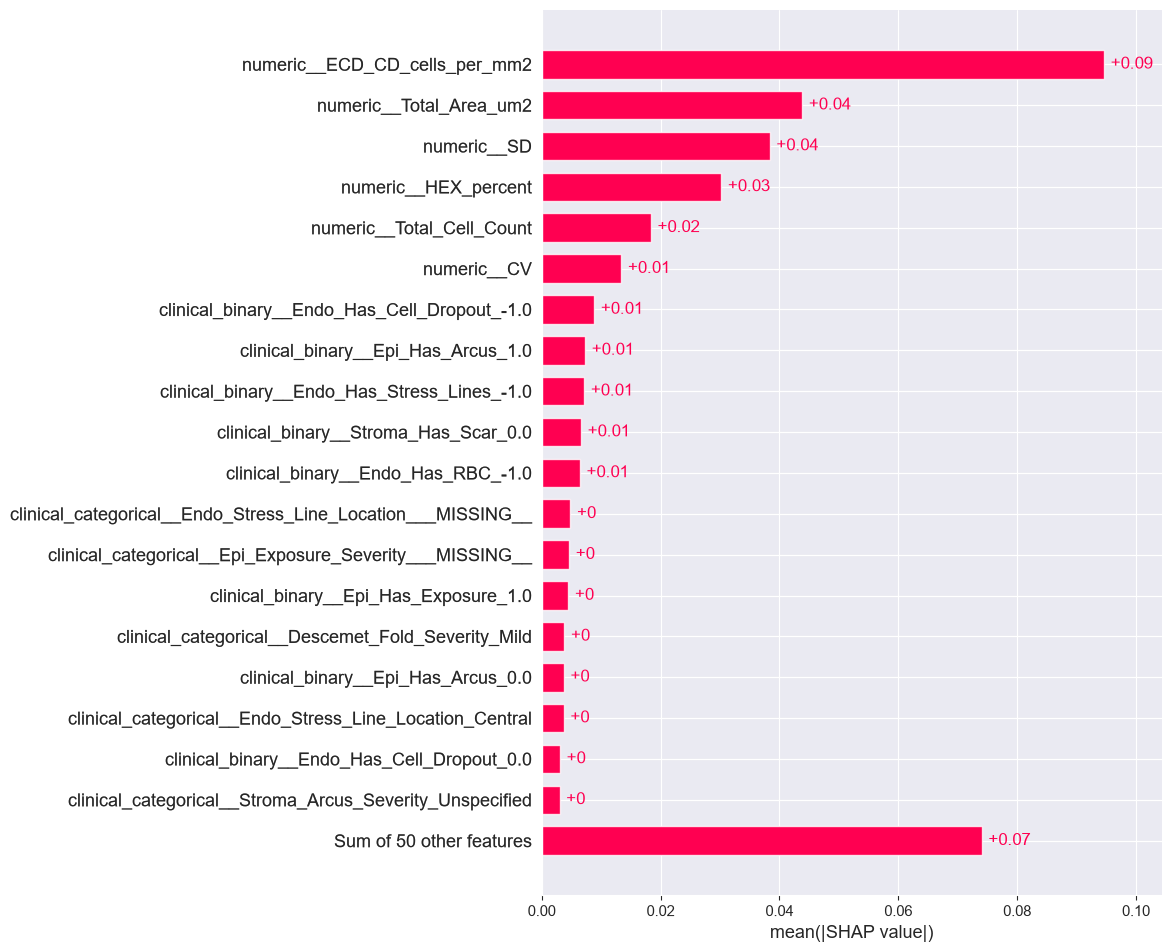

SHAP feature importance for grade A+


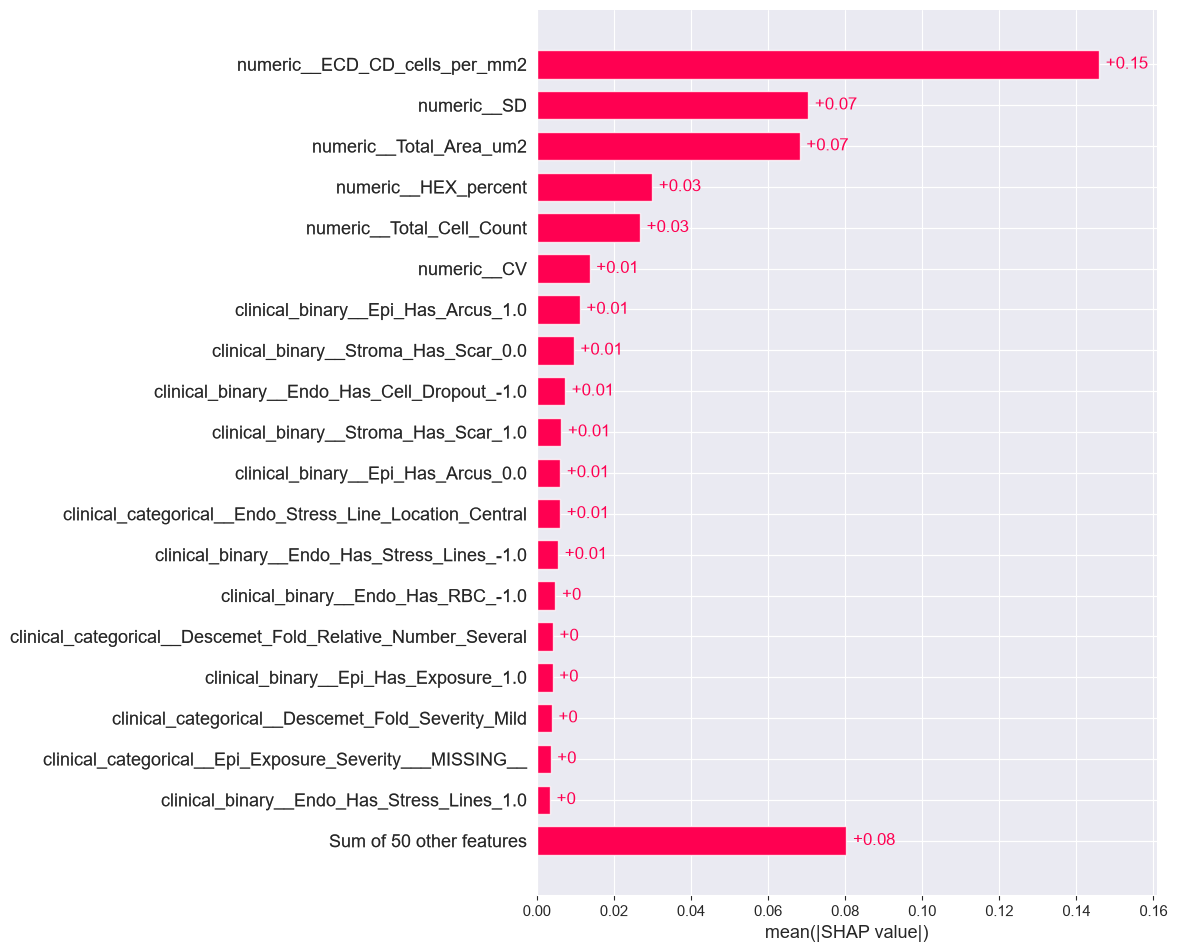

SHAP feature importance for grade B


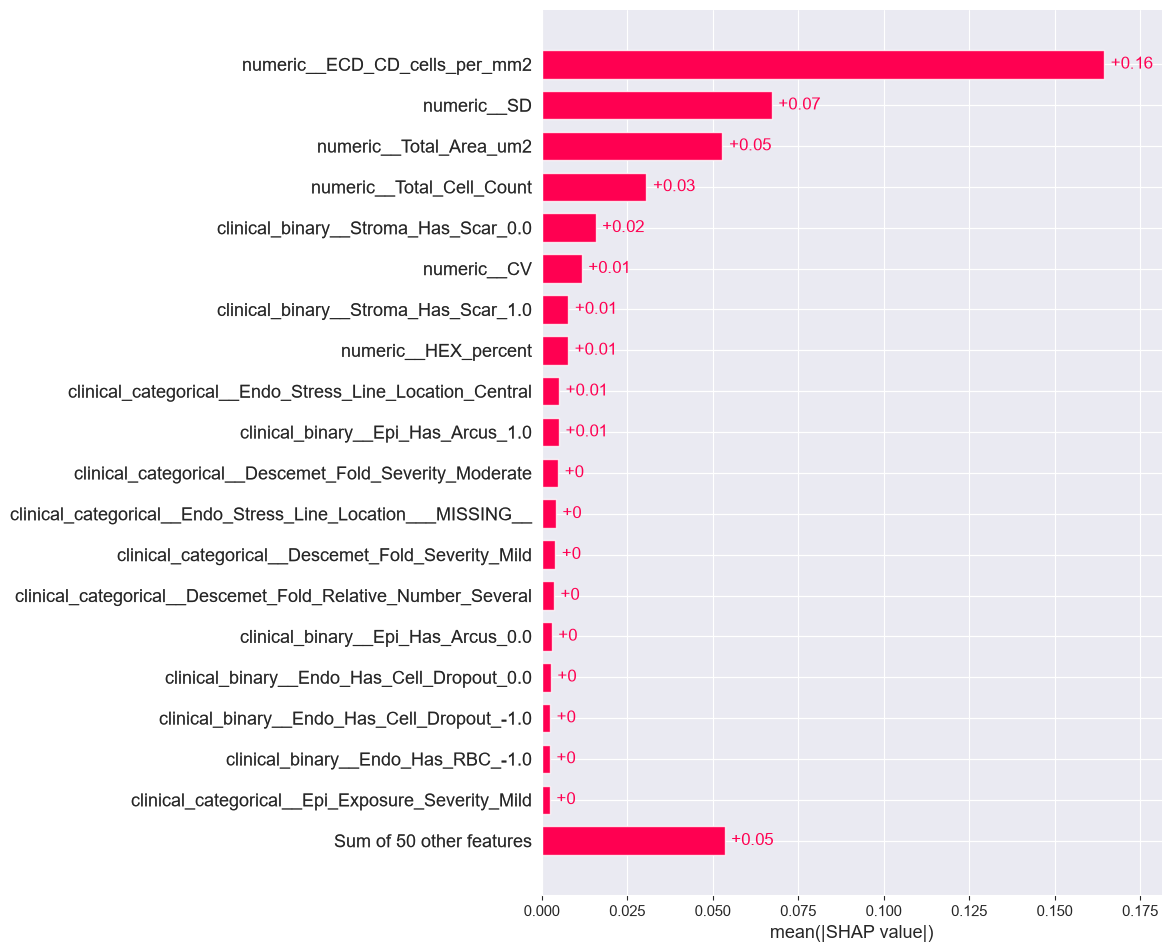

In [26]:
# Plot global feature importance separately for each class.
for class_index, class_name in enumerate(rf_model.classes_):
    print(f"SHAP feature importance for grade {class_name}")

    class_shap = shap_values[:, :, class_index]

    shap.plots.bar(
        class_shap,
        max_display=20
    )

SHAP beeswarm for grade A


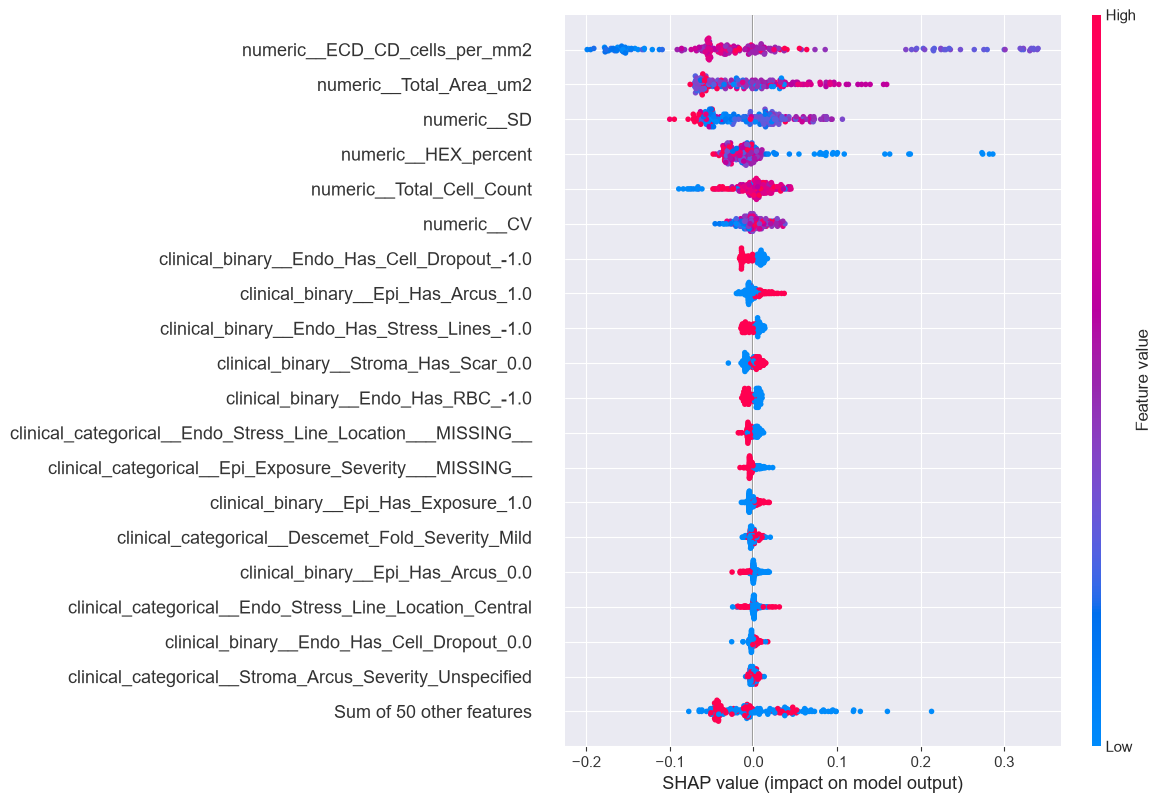

SHAP beeswarm for grade A+


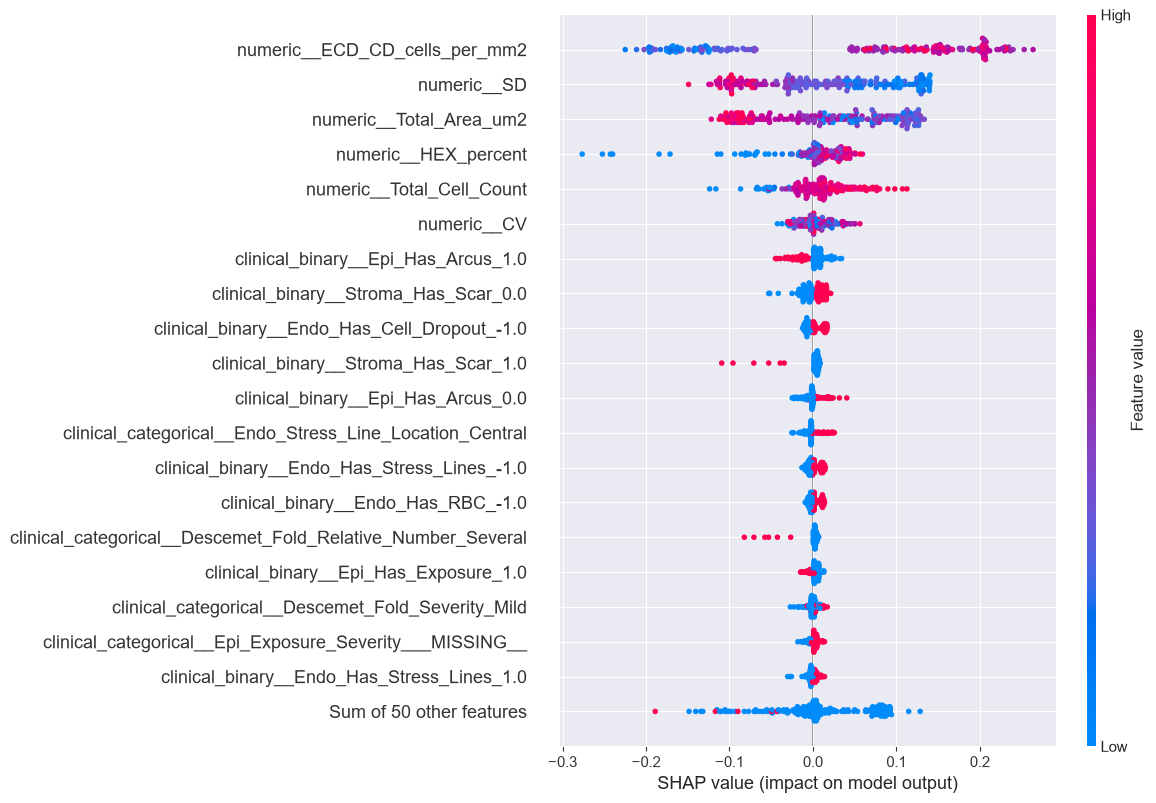

SHAP beeswarm for grade B


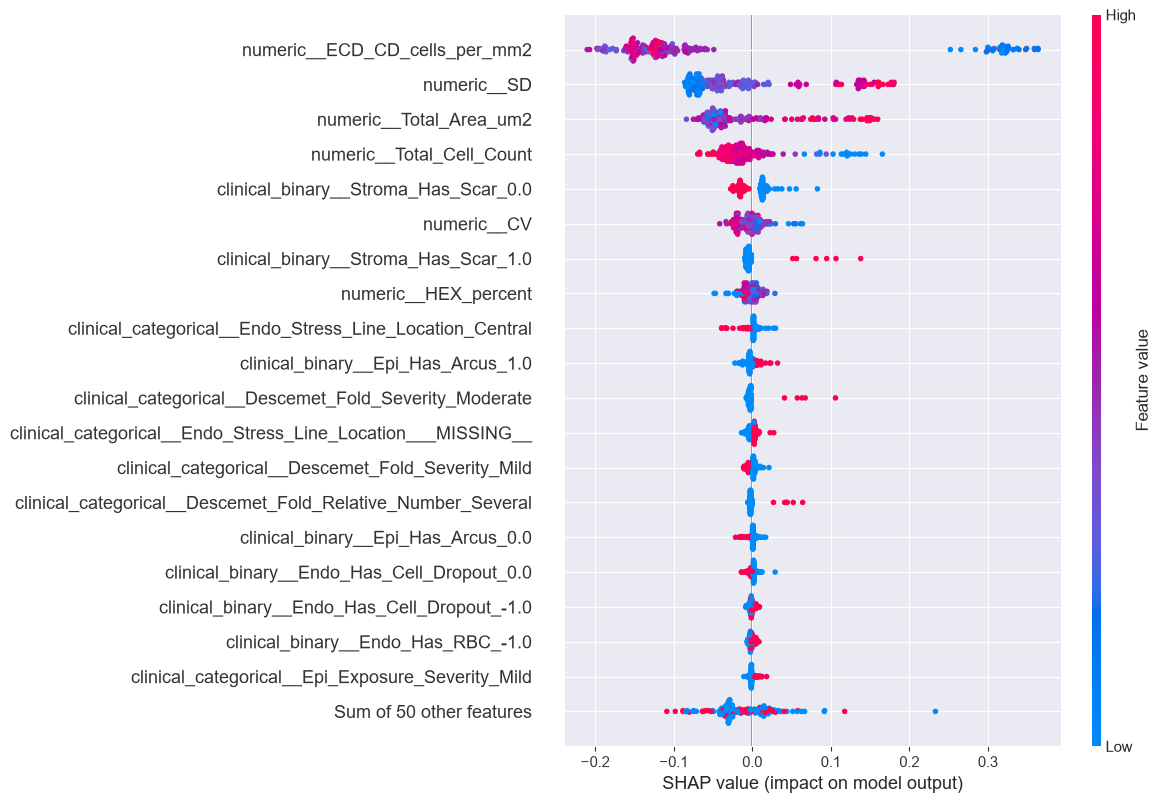

In [27]:
for class_index, class_name in enumerate(rf_model.classes_):
    print(f"SHAP beeswarm for grade {class_name}")

    class_shap = shap_values[:, :, class_index]

    shap.plots.beeswarm(
        class_shap,
        max_display=20
    )

In [28]:
# Aggregate absolute SHAP importance back to the original feature groups.
shap_importance = pd.DataFrame({
    "Encoded_Feature": feature_names,
    "Mean_Absolute_SHAP": np.abs(shap_values.values).mean(axis=(0, 2)),
})

def original_feature(encoded_name):
    for prefix in [
        "numeric__",
        "clinical_binary__",
        "clinical_categorical__",
    ]:
        if encoded_name.startswith(prefix):
            name = encoded_name[len(prefix):]
            if prefix != "numeric__":
                # Remove the one-hot encoded category suffix.
                name = name.rsplit("_", 1)[0]
            return name
    return encoded_name

shap_importance["Original_Feature"] = (
    shap_importance["Encoded_Feature"].apply(original_feature)
)

global_importance = (
    shap_importance.groupby("Original_Feature")["Mean_Absolute_SHAP"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print(global_importance.to_string(index=False))

                        Original_Feature  Mean_Absolute_SHAP
                    ECD_CD_cells_per_mm2            0.134995
                                      SD            0.058682
                          Total_Area_um2            0.054966
                        Total_Cell_Count            0.025255
                             HEX_percent            0.022611
                         Stroma_Has_Scar            0.017232
                           Epi_Has_Arcus            0.014208
                                      CV            0.012929
                   Endo_Has_Cell_Dropout            0.010310
               Endo_Stress_Line_Location            0.009604
                   Endo_Has_Stress_Lines            0.009371
                  Descemet_Fold_Severity            0.009253
                        Epi_Has_Exposure            0.007136
           Descemet_Fold_Relative_Number            0.006897
                       Stroma_Is_Compact            0.006664
                        

In [29]:
# Map every transformed column to its original input feature.
feature_mapping = []

for transformer_name, transformer, input_columns in (
    preprocessor.transformers_
):
    if transformer_name == "remainder":
        continue

    if transformer_name == "numeric":
        feature_mapping.extend(input_columns)

    elif transformer_name in ("clinical_binary", "clinical_categorical"):
        encoder = transformer.named_steps["encoder"]

        for input_column, categories in zip(
            input_columns, encoder.categories_
        ):
            feature_mapping.extend(
                [input_column] * len(categories)
            )

assert len(feature_mapping) == X_shap_transformed_df.shape[1]

# Aggregate mean absolute SHAP across encoded columns,
# then sum encoded-category contributions per original feature.
shap_importance = pd.DataFrame({
    "Original_Feature": feature_mapping,
    "Mean_Absolute_SHAP": np.abs(shap_values.values).mean(axis=(0, 2)),
})

global_importance = (
    shap_importance.groupby("Original_Feature")["Mean_Absolute_SHAP"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("Original feature count:", global_importance.shape[0])
print(global_importance.to_string(index=False))

Original feature count: 24
             Original_Feature  Mean_Absolute_SHAP
         ECD_CD_cells_per_mm2            0.134995
                           SD            0.058682
               Total_Area_um2            0.054966
             Total_Cell_Count            0.025255
                  HEX_percent            0.022611
              Stroma_Has_Scar            0.017232
                Epi_Has_Arcus            0.014208
    Endo_Stress_Line_Location            0.013419
                           CV            0.012929
        Endo_Has_Cell_Dropout            0.010310
       Descemet_Fold_Severity            0.010249
        Endo_Has_Stress_Lines            0.009371
Descemet_Fold_Relative_Number            0.008701
        Epi_Exposure_Severity            0.008082
             Epi_Has_Exposure            0.007136
            Stroma_Is_Compact            0.006664
                 Endo_Has_RBC            0.006548
             Stroma_Has_Arcus            0.005107
        Stroma_Arcus_Se

In [30]:
importance_path = (
    ms.SPLIT_PATH.parent / "shap_global_feature_importance.csv"
)

global_importance.to_csv(importance_path, index=False)

print("Saved SHAP importance to:", importance_path)
print("Original features:", len(global_importance))

Saved SHAP importance to: ..\data\processed\shap_global_feature_importance.csv
Original features: 24
